In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from astropy.io import fits
import glob
import copy
import scipy.ndimage as nd
from scipy.stats import ecdf
from scipy.optimize import minimize
from astropy.stats import sigma_clip
from scipy.stats import linregress


In [2]:
path_d = "/home/cperrot/Work/raw/JWST/Target/MAST/CALINTS/P03662/"
path_s = "/home/cperrot/Work/projet/JWST/Target/Calib/deadpixel/"
newd = 201
Y, X = np.ogrid[:newd, :newd]

lam = 11.40e-6 #µm
x0  = 119.77
y0  = 112.16

pixscale = 0.110
scale = [(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]

dr = 1.*lam/6.5*180.*3600./np.pi/pixscale
nbpixel = np.pi*dr**2

## data loading
sci1_fi    = glob.glob(path_d+"obs001/*_calints.fits")
sci2_fi    = glob.glob(path_d+"obs002/*_calints.fits")
ref_fi     = glob.glob(path_d+"obs004/*_calints.fits")
sci_bkg_fi = glob.glob(path_d+"obs003/*_calints.fits")
ref_bkg_fi = glob.glob(path_d+"obs005/*_calints.fits")

sci1_fi.sort()
sci2_fi.sort()
ref_fi.sort()
sci_bkg_fi.sort()
ref_bkg_fi.sort()

sci1 = fits.open(sci1_fi[0])[1].data
sci2 = fits.open(sci2_fi[0])[1].data
ref = []
for i in ref_fi: ref.append(fits.open(i)[1].data)
ref = np.array(ref)
sci_bkg = []
ref_bkg = []
for i in sci_bkg_fi : sci_bkg.append(fits.open(i)[1].data)
for i in ref_bkg_fi : ref_bkg.append(fits.open(i)[1].data)
sci_bkg = np.array(sci_bkg)
ref_bkg = np.array(ref_bkg)

/tmp/ipykernel_13943/3438081028.py:11: RuntimeWarning: All-NaN slice encountered
  plt.imshow(np.nanmedian(tmp,axis=0),origin='lower',cmap='inferno',interpolation='none',extent=scale)


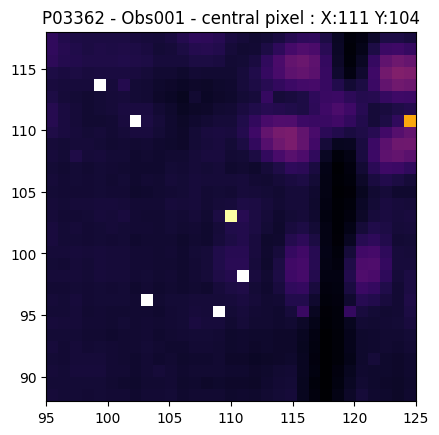

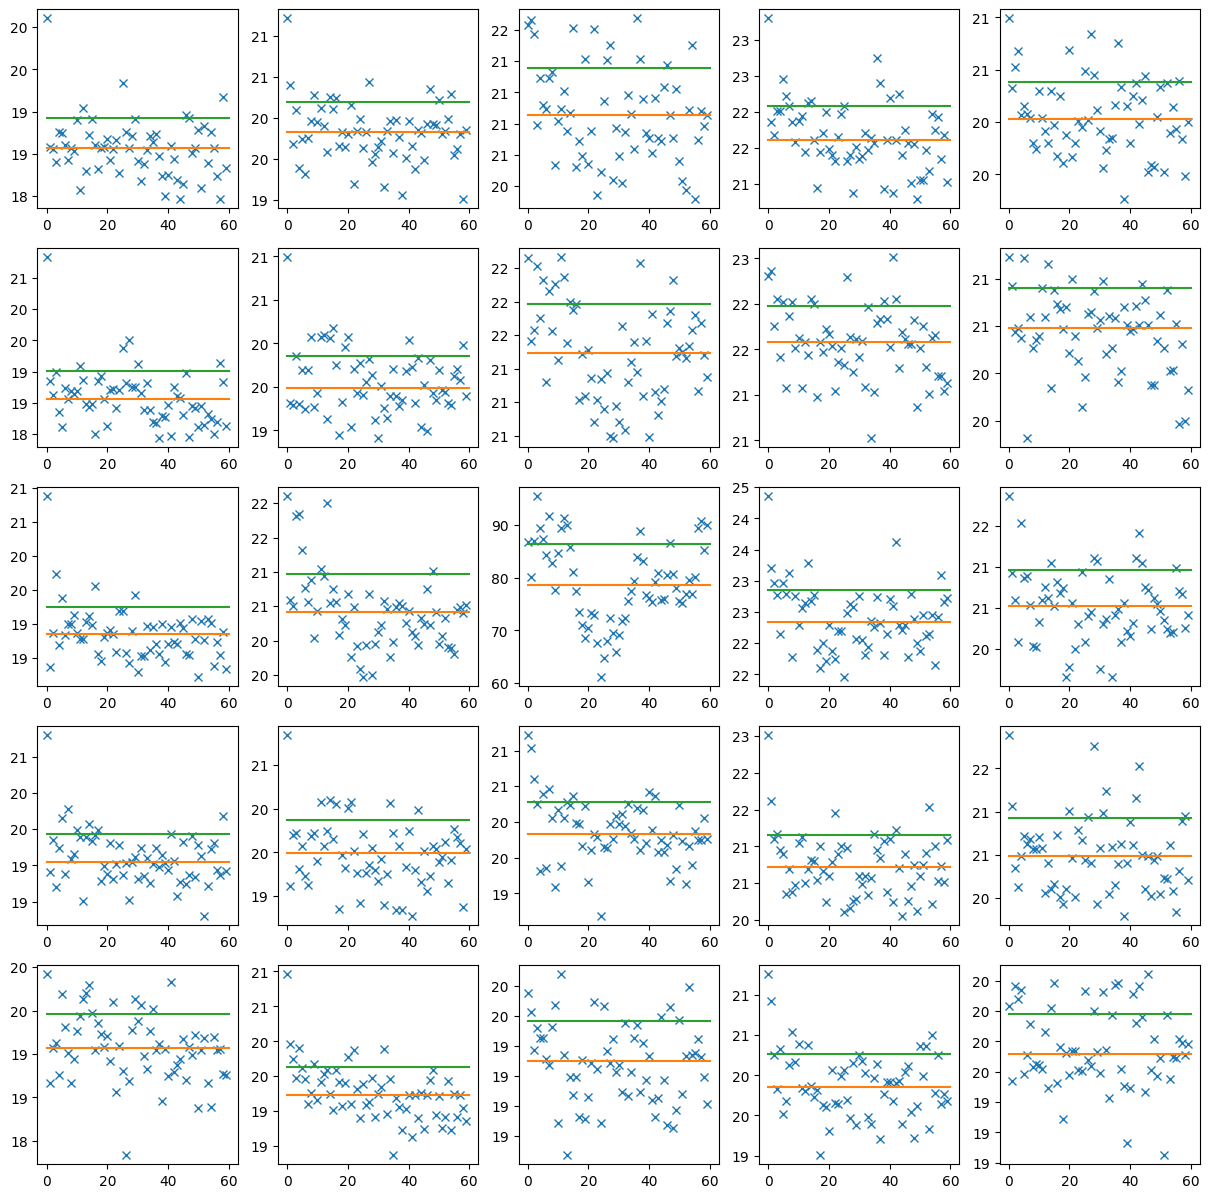

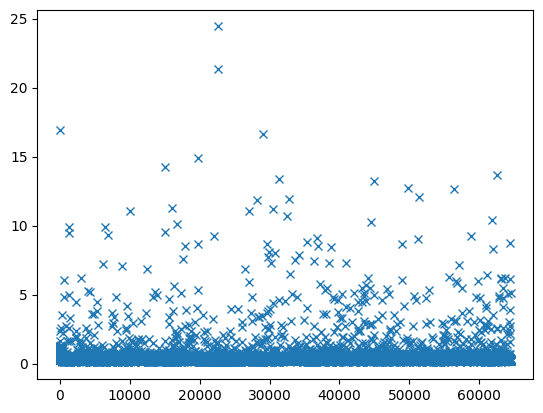

/tmp/ipykernel_13943/3438081028.py:35: RuntimeWarning: All-NaN slice encountered
  plt.plot(np.nanmedian(sci1,axis=0).flatten(),'x')


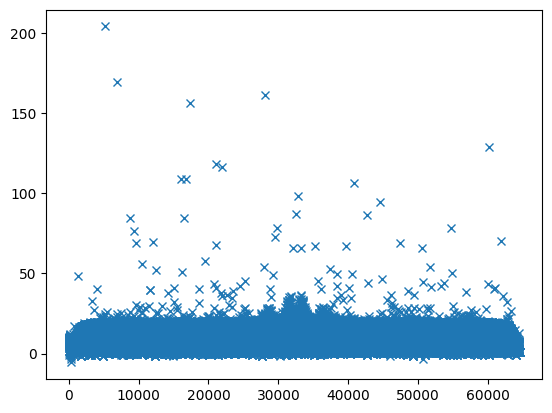

In [45]:


mid = [103,110]
ndata = np.shape(sci1)[0]


box = 31
tmp = sci1[:,mid[0]-box//2:mid[0]+box//2+1,mid[1]-box//2:mid[1]+box//2+1]
scale = [mid[1]-box//2,mid[1]+box//2,mid[0]-box//2,mid[0]+box//2]

fig = plt.Figure(figsize=(6,6))
plt.title("P03362 - Obs001 - central pixel : X:111 Y:104")
plt.imshow(np.nanmedian(tmp,axis=0),origin='lower',cmap='inferno',interpolation='none',extent=scale)
plt.show()

box = 5
tmp = sci1[:,mid[0]-box//2:mid[0]+box//2+1,mid[1]-box//2:mid[1]+box//2+1]



fig, axes = plt.subplots(box, box, figsize=(15, 15))
axes = axes.ravel()
tmp = tmp.reshape(ndata,box*box)

for i in range(box*box):
    axes[i].plot(tmp[:,i],'x')
    axes[i].plot([0,ndata],[np.median(tmp[:,i]),np.median(tmp[:,i])])
    axes[i].plot([0,ndata],[np.median(tmp[:,i])+np.std(tmp[:,i])*1,np.median(tmp[:,i])+np.std(tmp[:,i])*1])
    axes[i].yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f"{int(y)}") )
plt.show()




plt.plot(np.nanstd(sci1,axis=0).flatten(),'x')
plt.show()
plt.plot(np.nanmedian(sci1,axis=0).flatten(),'x')

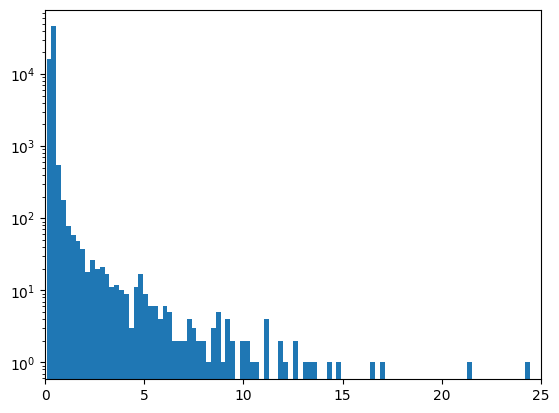

In [59]:
plt.hist(np.nanstd(sci1,axis=0).flatten(),100)
plt.xlim([0,25])
plt.yscale("log")
plt.show()

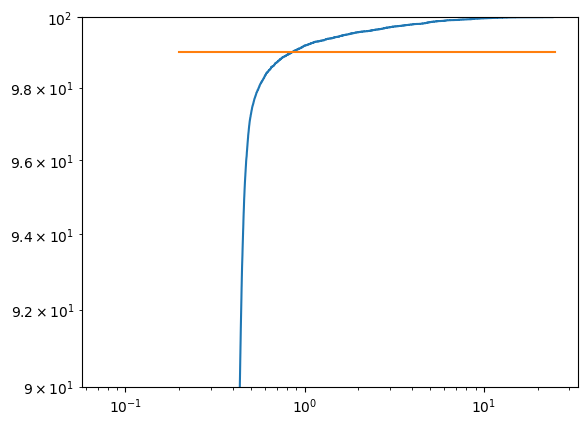

In [94]:
sorted_data = np.sort(np.nanstd(sci1,axis=0).flatten())
data_clean = sorted_data[~np.isnan(sorted_data)]
y = np.arange(1, len(data_clean) + 1) / len(data_clean)*100.
plt.step(data_clean, y, where='post')
plt.plot([0.2,25],[99,99])
plt.yscale('log')
plt.xscale('log')
plt.ylim([90,100])
plt.show()


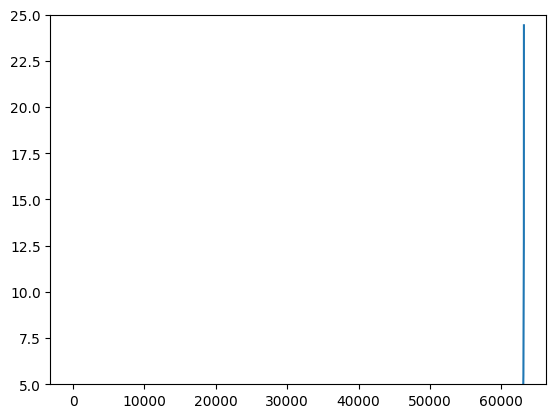

In [99]:
plt.plot(data_clean)
plt.ylim([5,25])
plt.show()


In [100]:
np.sum(data_clean > 5)

np.int64(93)

()

In [2]:
path_d = "/home/cperrot/Work/raw/JWST/Target/MAST/UNCAL/P03662/"
path_s = "/home/cperrot/Work/projet/JWST/Target/Calib/deadpixel/"
newd = 201
Y, X = np.ogrid[:newd, :newd]

lam = 11.40e-6 #µm
x0  = 119.77
y0  = 112.16
pixscale = 0.110
scale = [(newd/2.)*pixscale,-1*(newd/2.)*pixscale,-1*(newd/2.)*pixscale,(newd/2.)*pixscale]
dr = 1.*lam/6.5*180.*3600./np.pi/pixscale
nbpixel = np.pi*dr**2

## data loading
sci1_fi    = glob.glob(path_d+"obs006/*_uncal.fits")
sci2_fi    = glob.glob(path_d+"obs007/*_uncal.fits")
ref_fi     = glob.glob(path_d+"obs009/*_uncal.fits")
sci_bkg_fi = glob.glob(path_d+"obs008/*_uncal.fits")
ref_bkg_fi = glob.glob(path_d+"obs010/*_uncal.fits")

sci1_fi.sort()
sci2_fi.sort()
ref_fi.sort()
sci_bkg_fi.sort()
ref_bkg_fi.sort()

sci2 = fits.open(sci2_fi[0])[1].data


/tmp/ipykernel_46375/1977670291.py:8: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(vect-vect_s,200,(-100,100))


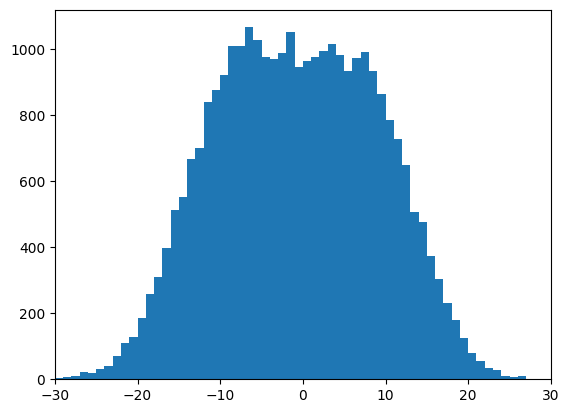

/home/cperrot/anaconda3/envs/jwst/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


1.107264493057972 0.11753825358035845 1.107264493057972 0.027851325837881163


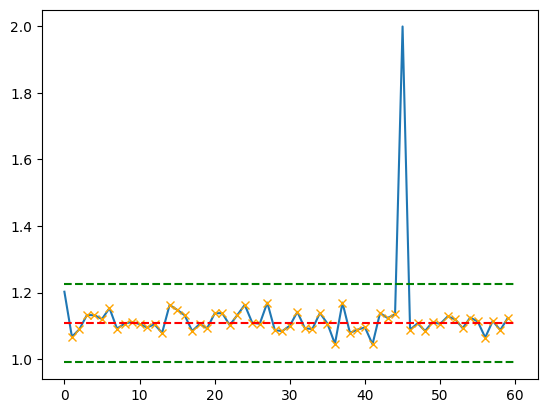

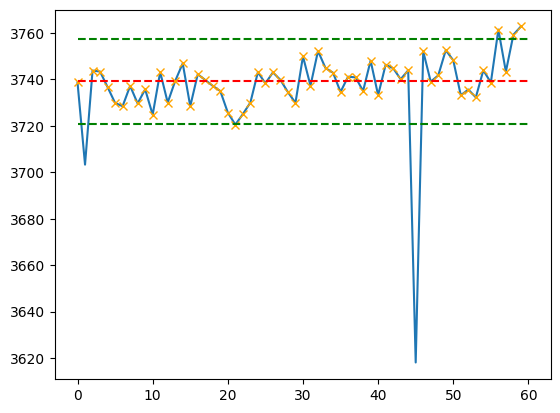

In [ ]:
xi = 123
yi = 151

vect = sci2[:, :, yi, xi].flatten()
vect = vect.astype(float) 
vect_s = np.roll(vect, shift=-1)

plt.hist(vect-vect_s,200,(-100,100))
plt.xlim([-30,30])
#plt.yscale("log")
plt.show()

x = range(500)  # Abscisses

pente  = np.ndarray(60)
origin = np.ndarray(60)
for i in range(60):
    y = sci2[i,:,yi,xi]
    # Fit linéaire
    result = linregress(x, y)
    pente[i], origin[i], r_value, p_value, std_err = result


med_pente = np.median(pente)
med_origin = np.median(origin)
std_pente = np.std(pente)
std_origin = np.std(origin)

pente_filtred = sigma_clip(pente, sigma=3, maxiters=5, cenfunc='median', stdfunc='std', masked=True)


plt.plot(range(60),pente)
plt.plot(range(60),pente_filtred,'x',color="orange")
plt.plot([0,60],[med_pente,med_pente],'--',color="red")
plt.plot([0,60],[med_pente+std_pente,med_pente+std_pente],'--',color="green")
plt.plot([0,60],[med_pente-std_pente,med_pente-std_pente],'--',color="green")
plt.show()


origin_filtred = sigma_clip(origin, sigma=3, maxiters=5, cenfunc='median', stdfunc='std', masked=True)


plt.plot(range(60),origin)
plt.plot(range(60),origin_filtred,'x',color="orange")
plt.plot([0,60],[med_origin,med_origin],'--',color="red")
plt.plot([0,60],[med_origin+std_origin,med_origin+std_origin],'--',color="green")
plt.plot([0,60],[med_origin-std_origin,med_origin-std_origin],'--',color="green")
plt.show()



In [ ]:
x = range(np.shape(sci2)[1])  # Abscisses
pente  = np.ndarray(np.shape(sci2)[0])
origin = np.ndarray(np.shape(sci2)[0])

med_pente  = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])
med_origin = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])
std_pente  = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])
std_origin = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])

med_pente_filtred  = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])
med_origin_filtred = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])
std_pente_filtred  = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])
std_origin_filtred = np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]])

for i in range(np.shape(sci2)[2]):
    print(100.*i/np.shape(sci2)[2],"%")
    for j in range(np.shape(sci2)[3]):
        vect = sci2[:, :, i, j].flatten()
        vect = vect.astype(float) 
        vect_s = np.roll(vect, shift=-1)

        #plt.hist(vect-vect_s,200,(-100,100))
        #plt.xlim([-30,30])
        #plt.yscale("log")
        #plt.show()

        for k in range(np.shape(sci2)[0]):
            y = sci2[k,:,i,j]
            pente[k], origin[k], r_value, p_value, std_err = linregress(x, y)


        med_pente[i,j]  = np.median(pente)
        med_origin[i,j] = np.median(origin)
        std_pente[i,j]  = np.std(pente)
        std_origin[i,j] = np.std(origin)

        pente_filtred  = sigma_clip(pente, sigma=3, maxiters=5, cenfunc='median', stdfunc='std', masked=True)
        origin_filtred = sigma_clip(origin, sigma=3, maxiters=5, cenfunc='median', stdfunc='std', masked=True)

        med_pente_filtred[i,j]  = np.ma.median(pente_filtred)
        med_origin_filtred[i,j] = np.ma.median(origin_filtred)
        std_pente_filtred[i,j]  = np.ma.std(pente_filtred)
        std_origin_filtred[i,j] = np.ma.std(origin_filtred)


imp.save_fits(med_pente, path_s+"med_pente.fits")
imp.save_fits(med_origin, path_s+"med_origin.fits")
imp.save_fits(std_pente, path_s+"std_pente.fits")
imp.save_fits(std_origin, path_s+"std_origin.fits")

imp.save_fits(med_pente_filtred, path_s+"med_pente_filtred.fits")
imp.save_fits(med_origin_filtred, path_s+"med_origin_filtred.fits")
imp.save_fits(std_pente_filtred, path_s+"std_pente_filtred.fits")
imp.save_fits(std_origin_filtred, path_s+"std_origin_filtred.fits")



0.0 %
0.44642857142857145 %
0.8928571428571429 %
1.3392857142857142 %
1.7857142857142858 %
2.232142857142857 %
2.6785714285714284 %
3.125 %
3.5714285714285716 %
4.017857142857143 %
4.464285714285714 %
4.910714285714286 %
5.357142857142857 %
5.803571428571429 %
6.25 %
6.696428571428571 %
7.142857142857143 %
7.589285714285714 %
8.035714285714286 %
8.482142857142858 %
8.928571428571429 %
9.375 %
9.821428571428571 %
10.267857142857142 %
10.714285714285714 %
11.160714285714286 %
11.607142857142858 %
12.053571428571429 %
12.5 %
12.946428571428571 %
13.392857142857142 %
13.839285714285714 %
14.285714285714286 %
14.732142857142858 %
15.178571428571429 %
15.625 %
16.071428571428573 %
16.517857142857142 %
16.964285714285715 %
17.410714285714285 %
17.857142857142858 %
18.303571428571427 %
18.75 %
19.196428571428573 %
19.642857142857142 %
20.089285714285715 %
20.535714285714285 %
20.982142857142858 %
21.428571428571427 %
21.875 %
22.321428571428573 %
22.767857142857142 %
23.214285714285715 %
23.66

In [3]:
# recharge des données pour pas refaire tourner
med_pente  = fits.open(path_s+"med_pente.fits")[0].data
med_origin = fits.open(path_s+"med_origin.fits")[0].data
std_pente  = fits.open(path_s+"std_pente.fits")[0].data
std_origin = fits.open(path_s+"std_origin.fits")[0].data

med_pente_filtred  = fits.open(path_s+"med_pente_filtred.fits")[0].data
med_origin_filtred = fits.open(path_s+"med_origin_filtred.fits")[0].data
std_pente_filtred  = fits.open(path_s+"std_pente_filtred.fits")[0].data
std_origin_filtred = fits.open(path_s+"std_origin_filtred.fits")[0].data

/tmp/ipykernel_33694/2561502523.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(std_pente_filtred.flatten(),10000,(1e-3,2))


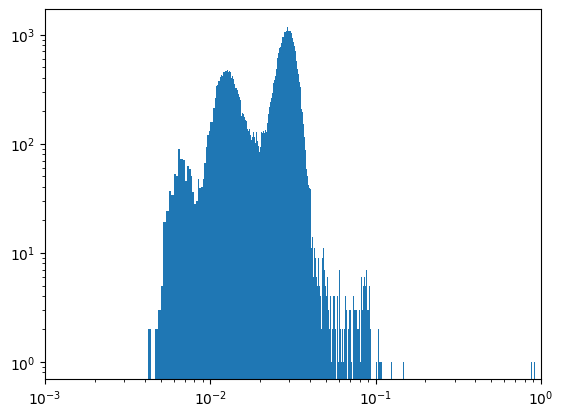

In [38]:
plt.hist(std_pente_filtred.flatten(),10000,(1e-3,2))
plt.xlim([1e-3,1])
plt.yscale("log")
plt.xscale("log")
plt.show()

(60, 500, 224, 288)


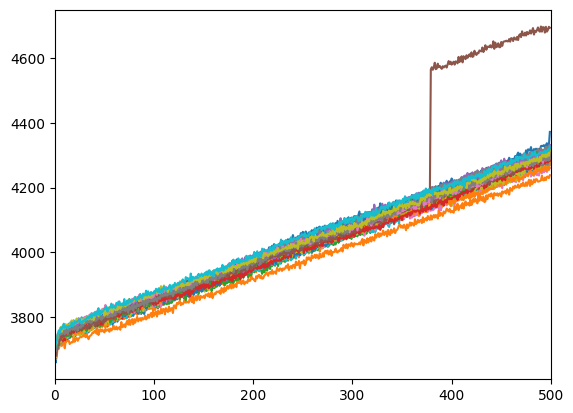

In [74]:
print(np.shape(sci2))
for i in range(60):
    plt.plot(sci2[i,:,yi,xi],)
plt.xlim([0,500])
#plt.ylim([3500,4500])
plt.show()

In [ ]:
np.shape(np.ndarray([np.shape(sci2)[2],np.shape(sci2)[3]]))

(224, 288)

In [23]:
np.shape(sci2)

(60, 500, 224, 288)